In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from Bio.Align import substitution_matrices
from Bio import SeqIO
from datetime import datetime
from itertools import chain

In [111]:
def load_fasta(fasta_path):
    print(f"Loading FASTA: {fasta_path}...")
    all_parsed_data = []
    for record in SeqIO.parse(fasta_path, "fasta"):
        fields = record.id.split('|')
        if len(fields) < 6:
            continue
        unique_id = fields[0].strip()
        subtype   = fields[1].strip()
        clade     = fields[2].strip()
        date_str  = fields[3].strip()
        country   = fields[4].strip()
        zone      = fields[5].strip()
        try:
            date     = datetime.strptime(date_str, '%Y-%m-%d')
            # 1. Get the raw sequence and remove gaps/stops
            #raw_seq = str(record.seq).replace('-', '').replace('*', '')
            
            # Keep gaps (-), only remove stop codons (*)
            raw_seq = str(record.seq).replace('*', '')
            
        # 2. Check length and cut conditionally
            if len(raw_seq) >= 553:
                sequence = raw_seq[16:]
            else:
                sequence = raw_seq
                
            all_parsed_data.append(dict(
                date=date, sequence=sequence,
                id_full_header=record.id, unique_id=unique_id,
                clade=clade, subtype=subtype, country=country, zone=zone
            ))
        except ValueError:
            continue
    df = pd.DataFrame(all_parsed_data)
    print(f"Total records: {len(df)}")
    return df

df_fasta = load_fasta("h3n2_clean.fasta")

Loading FASTA: h3n2_clean.fasta...
Total records: 193102


In [112]:
def calc_hamming_distance(seq1, seq2):
    """Calculates Hamming distance (counts direct mismatches)."""
    dist = 0
    for a, b in zip(seq1, seq2):
        if a != b:
            dist += 1
    return dist

# --- SETUP EPITOPE INDICES ---
epitope_sites = {
    'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
    'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
    'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
    'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
    'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
}
ALL_EPITOPE_POSITIONS_1BASED = sorted(set(chain.from_iterable(epitope_sites.values())))
EPITOPE_INDICES_0BASED = [p - 1 for p in ALL_EPITOPE_POSITIONS_1BASED]

In [113]:
# --- 1. LOAD DATA ---
df_hi = pd.read_csv("D_H3N2(H3N2).csv", low_memory=False)
def categorize_hi_titre(val):
    if pd.isna(val):
        return "Missing/Invalid"
    
    val_str = str(val).strip()
    
    # 1. Handle Less-Than Values (Censored Lows)
    if val_str.startswith('<'):
        try:
            num = float(val_str.replace('<', '').replace('=', ''))
            # Captures <10, <20, <40 standard baseline reports
            if num <= 40:
                return "<40"
            # If a lab reports <80, it's ambiguous (could be 40, 20, 10, or 0)
            # We conservatively bin it as 40, but flag anything higher as invalid/ambiguous
            elif num <= 80:
                return "40"
            else:
                return "Ambiguous" 
        except ValueError:
            return "Invalid"
            
    # 2. Handle Greater-Than Values (Censored Highs)
    # Automatically pool all censored high values (e.g., >640, >1280, 1280+) into the top tier
    if val_str.startswith('>') or val_str.endswith('+'):
        return ">=640"
            
    # 3. Handle Standard & Intermediate Numeric Values Fine-Grained
    try:
        num = float(val_str)
        if num < 40:
            return "<40"
        elif num < 80:
            return "40"
        elif num < 160:
            return "80"
        elif num < 320:
            return "160"
        elif num < 640:
            return "320"
        else:
            # Pools 640, 1280, 2560, etc., into a single high-protection tier
            return ">=640" 
    except ValueError:
        return "Invalid"

# Apply and check the clean breakdown
df_hi['Titre_Group'] = df_hi['HI titre'].apply(categorize_hi_titre)

# Optional: Force categorical ordering so your plots automatically sort correctly from low to high
titer_order = ["<40", "40", "80", "160", "320", ">=640"]
df_hi['Titre_Group'] = pd.Categorical(df_hi['Titre_Group'], categories=titer_order, ordered=True)

print(df_hi['Titre_Group'].value_counts(sort=False))

Titre_Group
<40      16698
40       23975
80       34226
160      42205
320      34760
>=640    35442
Name: count, dtype: int64


In [114]:
df_hi['HI titre'].value_counts(sort=False)


HI titre
5120       1152
1280       9509
2560       3042
80        34131
160       42109
320       34653
640       21332
40        23895
ND         1887
<40       14610
20          260
10           52
0             3
<40        1416
180           7
60           37
<40           3
321           1
6340          4
1602          1
120          53
>5120        26
10240        44
>             2
440           2
>2560        83
<20         243
3             1
16            8
2             1
9             1
1             1
460           1
<80          17
>10240       17
230           1
<10          36
1024         30
32           13
8            13
<8           16
128          37
256          30
512          28
64           22
960          25
30           15
480          53
100           4
50            4
240          37
1920         49
<             1
200           9
<30           2
400           7
800          10
>1280         3
1000          2
3162          2
1585          3
789           1

In [115]:
# Creates a table counting the occurrences of raw values in the new bins
# We use head(20) to just check the most common raw values
crosstab_check = pd.crosstab(df_hi['HI titre'], df_hi['Titre_Group'])
print(crosstab_check.sort_values(by=crosstab_check.columns.tolist(), ascending=False))

Titre_Group    <40     40     80    160    320  >=640
HI titre                                             
<40          14610      0      0      0      0      0
<40           1416      0      0      0      0      0
20             260      0      0      0      0      0
<20            243      0      0      0      0      0
10              52      0      0      0      0      0
<10             36      0      0      0      0      0
<8              16      0      0      0      0      0
30              15      0      0      0      0      0
32              13      0      0      0      0      0
8               13      0      0      0      0      0
16               8      0      0      0      0      0
0                3      0      0      0      0      0
15               3      0      0      0      0      0
<40              3      0      0      0      0      0
<30              2      0      0      0      0      0
1                1      0      0      0      0      0
2                1      0   

In [116]:
print("Loading Metadata...")
df_metadata = pd.read_csv("combined_data.csv", low_memory=False)

Loading Metadata...


In [117]:
# --- 2. CREATE DICTIONARIES (MAPPINGS) ---
name_to_id = dict(zip(
    df_metadata['Isolate_Name'].astype(str).str.strip(), 
    df_metadata['Isolate_Id'].astype(str).str.strip()
))

id_to_seq = dict(zip(
    df_fasta['unique_id'].astype(str).str.strip(), 
    df_fasta['sequence']
))

all_pairs_info = []

for _, row in df_hi.iterrows():
    v_name = str(row['VirusStrain']).strip()
    s_name = str(row['SerumStrain']).strip()
    v_id = name_to_id.get(v_name)
    s_id = name_to_id.get(s_name)
    
    v_ok = (v_id in id_to_seq) if v_id else False
    s_ok = (s_id in id_to_seq) if s_id else False
    
    # Determine exact status for every single row
    if v_ok and s_ok:
        status = 'Fully Matched'
    elif not v_ok and not s_ok:
        status = 'Missing Both ID/Seq'
    elif not v_ok:
        status = 'Missing Virus ID/Seq'
    else:
        status = 'Missing Serum ID/Seq'
        
    all_pairs_info.append({
        'VirusStrain': v_name,
        'SerumStrain': s_name,
        'PublishedDate': row.get('PublishedDate', np.nan),
        'SerumType': row.get('SerumType', np.nan),
        'Status': status
    })

# Convert the results back to a DataFrame
df_all_summary = pd.DataFrame(all_pairs_info)

# Calculate totals
total_rows = len(df_all_summary)
matched_rows = len(df_all_summary[df_all_summary['Status'] == 'Fully Matched'])
unmatched_rows = total_rows - matched_rows

print(f"\n--- ALL PAIRS DIAGNOSTICS ---")
print(f"Total rows checked: {total_rows}")
print(f"Successfully matched rows: {matched_rows}")
print(f"Unmatched rows: {unmatched_rows}")

if not df_all_summary.empty:
    print("\nBreakdown of ALL pairs by PublishedDate, SerumType, and Status:")
    summary_table = df_all_summary.groupby(['PublishedDate', 'SerumType', 'Status']).size().reset_index(name='Count')
    print(summary_table.to_string(index=False))


--- ALL PAIRS DIAGNOSTICS ---
Total rows checked: 189313
Successfully matched rows: 122973
Unmatched rows: 66340

Breakdown of ALL pairs by PublishedDate, SerumType, and Status:
PublishedDate SerumType               Status  Count
         1972    ferret  Missing Both ID/Seq     83
         1974    ferret  Missing Both ID/Seq    169
         1975    ferret  Missing Both ID/Seq    261
         1976    ferret  Missing Both ID/Seq     64
         1977    ferret  Missing Both ID/Seq     81
         1980    ferret  Missing Both ID/Seq     25
         1982    ferret  Missing Both ID/Seq     16
         1983    ferret  Missing Both ID/Seq    254
         1985    ferret  Missing Both ID/Seq     25
         1986    ferret  Missing Both ID/Seq     36
         1988    ferret  Missing Both ID/Seq    156
         1990    ferret  Missing Both ID/Seq     30
         1991    ferret  Missing Both ID/Seq     25
         1992    ferret  Missing Both ID/Seq     16
         1993    ferret  Missing Both ID/

In [118]:
if not df_all_summary.empty:
    print("\nBreakdown of ALL pairs by Status:")
    summary_table = df_all_summary.groupby([ 'Status']).size().reset_index(name='Count')
    print(summary_table.to_string(index=False))


Breakdown of ALL pairs by Status:
              Status  Count
       Fully Matched 122973
 Missing Both ID/Seq  26632
Missing Serum ID/Seq  16752
Missing Virus ID/Seq  22956


In [119]:
# --- 5. SAVE UNIQUE UNMATCHED NAMES TO TXT FILE ---

# 1. Grab all the Virus names from rows where the Virus was missing
missing_viruses = df_all_summary.loc[
    df_all_summary['Status'].isin(['Missing Virus ID/Seq', 'Missing Both ID/Seq']), 
    'VirusStrain'
].dropna().unique()

# 2. Grab all the Serum names from rows where the Serum was missing
missing_sera = df_all_summary.loc[
    df_all_summary['Status'].isin(['Missing Serum ID/Seq', 'Missing Both ID/Seq']), 
    'SerumStrain'
].dropna().unique()

# 3. Combine both lists into a single mathematical set to remove any duplicates
unmatched_unique_strains = set(missing_viruses).union(set(missing_sera))
unmatched_list = sorted(list(unmatched_unique_strains))

# 4. Save to text file
output_file = "unmatched_strains.txt"

with open(output_file, "w") as file:
    for name in unmatched_list:
        file.write(f"{name}\n")

print(f"\nSuccessfully saved {len(unmatched_list)} unique unmatched names to '{output_file}'")


Successfully saved 3383 unique unmatched names to 'unmatched_strains.txt'


In [120]:
plot_data = []
print("\nCalculating Hamming distances (All & Epitopes) for matched pairs...")

for _, row in df_hi.iterrows():
    v_name = str(row['VirusStrain']).strip()
    s_name = str(row['SerumStrain']).strip()
    
    # Grab the cleaned category we made earlier
    titre_group = row.get('Titre_Group', np.nan) 
    
    # Skip if missing virus/serum names
    if pd.isna(row['VirusStrain']) or pd.isna(row['SerumStrain']):
        continue
        
    v_id = name_to_id.get(v_name)
    s_id = name_to_id.get(s_name)
    
    # Check if FULLY MATCHED (both IDs exist in the fasta dictionary)
    if v_id in id_to_seq and s_id in id_to_seq:
        
        # Skip rows where the titer was unreadable (e.g., "ND", "Invalid")
        if pd.isna(titre_group) or titre_group in ["Invalid", "Missing/Invalid", "Ambiguous"]:
            continue
            
        v_seq = id_to_seq[v_id]
        s_seq = id_to_seq[s_id]
            
        # 1. Full Sequence Distance
        dist_all = calc_hamming_distance(v_seq, s_seq)
        
        # 2. Epitope-Only Distance
        v_seq_epi = "".join([v_seq[i] for i in EPITOPE_INDICES_0BASED if i < len(v_seq)])
        s_seq_epi = "".join([s_seq[i] for i in EPITOPE_INDICES_0BASED if i < len(s_seq)])
        dist_epi = calc_hamming_distance(v_seq_epi, s_seq_epi)
        
        plot_data.append({
            'Virus_Name': v_name,
            'Serum_Name': s_name,
            'Distance_All': dist_all,
            'Distance_Epitope': dist_epi,
            'Titre_Group': titre_group,      # Save the cleaned category for plotting
            'HI_Titre_Raw': row['HI titre']  # Keep the raw original text just in case
        })

df_plot = pd.DataFrame(plot_data)

# Optional: Re-apply the categorical ordering so it's ready for the raincloud plot
titer_order = ["<40", "40", "80", "160", "320", ">=640"]
df_plot['Titre_Group'] = pd.Categorical(df_plot['Titre_Group'], categories=titer_order, ordered=True)

print(f"Successfully calculated distances for {len(df_plot)} fully matched pairs.")


Calculating Hamming distances (All & Epitopes) for matched pairs...
Successfully calculated distances for 121757 fully matched pairs.


In [86]:
df_plot = df_plot[df_plot['Virus_Name'] != df_plot['Serum_Name']].copy()

print(f"Successfully calculated distances for {len(df_plot)} heterologous pairs.")

Successfully calculated distances for 80097 heterologous pairs.


In [87]:
#df_plot['Titre_Group'] = df_plot['HI_Titre'].apply(categorize_hi_titre) # or apply to raw column before parsing
df_plot.groupby('Titre_Group')['Titre_Group'].count()

/tmp/ipykernel_2656383/960234062.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_plot.groupby('Titre_Group')['Titre_Group'].count()


Titre_Group
<40       6271
40       11957
80       16168
160      18556
320      15002
>=640    12143
Name: Titre_Group, dtype: int64

/tmp/ipykernel_2656383/2931625919.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups_for_test = [group['Distance_All'].values for name, group in df_grouped.groupby('Titre_Group')]
/tmp/ipykernel_2656383/2931625919.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Kruskal-Wallis Test across Titer Groups -> Stat: 41075.16, p-value: 0.00e+00


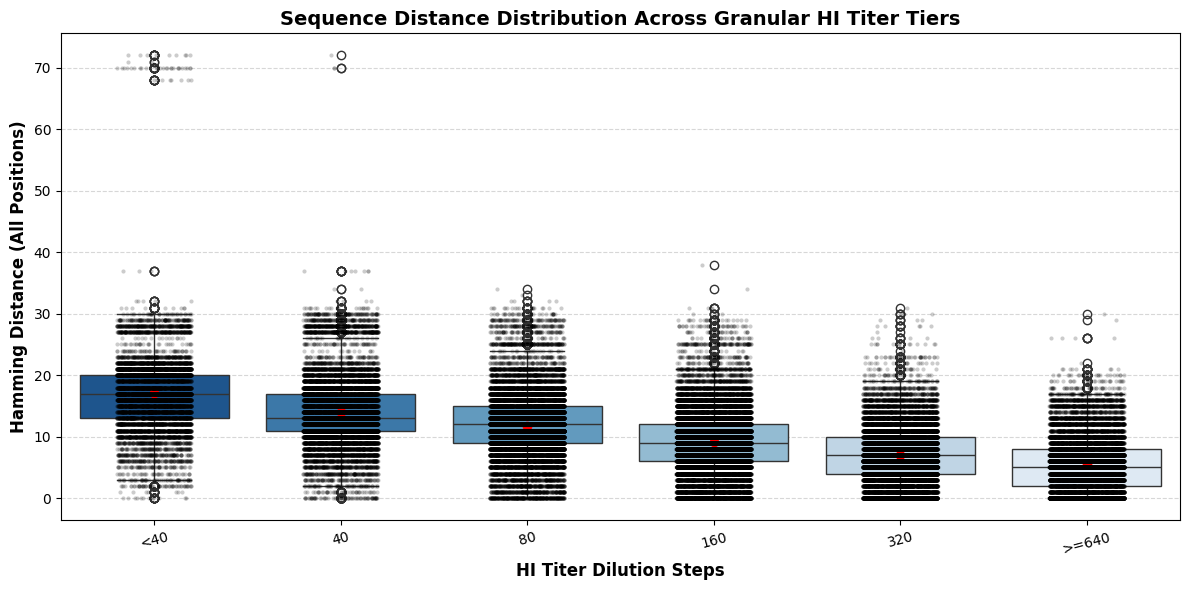

In [121]:
from scipy.stats import kruskal
import matplotlib.pyplot as plt
import seaborn as sns

# Define the new fine-grained valid groups in proper biological order
valid_groups = [
    '<40',
    '40', 
    '80', 
    '160', 
    '320', 
    '>=640'
]

# Filter out Invalid, Missing, and the sparse '<40' entry
df_grouped = df_plot[df_plot['Titre_Group'].isin(valid_groups)].copy()

# --- 2. STATISTICAL TEST FOR ASSOCIATION (Kruskal-Wallis) ---
# Tests if the distance distributions differ significantly across the titer groups
groups_for_test = [group['Distance_All'].values for name, group in df_grouped.groupby('Titre_Group')]
stat, p_value = kruskal(*groups_for_test)
print(f"Kruskal-Wallis Test across Titer Groups -> Stat: {stat:.2f}, p-value: {p_value:.2e}")

# --- 3. BETTER PLOT: BOXPLOT + STRIPPLOT ---
plt.figure(figsize=(12, 6))

# Draw boxplot showing the median and quartiles of distance for each group
sns.boxplot(
    data=df_grouped, 
    x='Titre_Group', 
    y='Distance_All', 
    order=valid_groups,
    palette='Blues_r', 
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"6"}
)

# Overlay a stripplot to show individual data points transparently
sns.stripplot(
    data=df_grouped, 
    x='Titre_Group', 
    y='Distance_All', 
    order=valid_groups,
    color='black', 
    alpha=0.2, 
    jitter=0.2, 
    size=3
)

plt.title('Sequence Distance Distribution Across Granular HI Titer Tiers', fontsize=14, weight='bold')
plt.xlabel('HI Titer Dilution Steps', fontsize=12, weight='bold')
plt.ylabel('Hamming Distance (All Positions)', fontsize=12, weight='bold')
plt.xticks(rotation=15, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.savefig("HI_vs_Allpos_distance.png", dpi = 300)
plt.show()

In [125]:
import scikit_posthocs as sp

# Run Dunn's test with Benjamini-Hochberg (bh) correction for multiple testing
dunn_results = sp.posthoc_dunn(
    df_grouped, 
    val_col='Distance_Epitope', 
    group_col='Titre_Group', 
    p_adjust='bonferroni' # or 'fdr_bh' for Benjamini-Hochberg
)

print("Dunn's Test Pairwise P-Values:")
print(dunn_results)

Dunn's Test Pairwise P-Values:
                 <40             40             80  160            320  \
<40     1.000000e+00  6.577714e-167   0.000000e+00  0.0   0.000000e+00   
40     6.577714e-167   1.000000e+00  6.639082e-241  0.0   0.000000e+00   
80      0.000000e+00  6.639082e-241   1.000000e+00  0.0   0.000000e+00   
160     0.000000e+00   0.000000e+00   0.000000e+00  1.0   0.000000e+00   
320     0.000000e+00   0.000000e+00   0.000000e+00  0.0   1.000000e+00   
>=640   0.000000e+00   0.000000e+00   0.000000e+00  0.0  8.284009e-108   

               >=640  
<40     0.000000e+00  
40      0.000000e+00  
80      0.000000e+00  
160     0.000000e+00  
320    8.284009e-108  
>=640   1.000000e+00  


In [80]:
dunn_results2 = sp.posthoc_dunn(
    df_grouped, 
    val_col='Distance_All', 
    group_col='Titre_Group', 
    p_adjust='bonferroni' # or 'fdr_bh' for Benjamini-Hochberg
)

print("Dunn's Test Pairwise P-Values:")
print(dunn_results2)

Dunn's Test Pairwise P-Values:
                 160            320            40            80           <40  \
160     1.000000e+00  6.959312e-309  0.000000e+00  0.000000e+00  5.826698e-44   
320    6.959312e-309   1.000000e+00  0.000000e+00  0.000000e+00  6.997688e-70   
40      0.000000e+00   0.000000e+00  1.000000e+00  0.000000e+00  1.304491e-08   
80      0.000000e+00   0.000000e+00  0.000000e+00  1.000000e+00  5.043250e-23   
<40     5.826698e-44   6.997688e-70  1.304491e-08  5.043250e-23  1.000000e+00   
>=640   0.000000e+00   1.751245e-06  0.000000e+00  0.000000e+00  2.138250e-74   

              >=640  
160    0.000000e+00  
320    1.751245e-06  
40     0.000000e+00  
80     0.000000e+00  
<40    2.138250e-74  
>=640  1.000000e+00  


/tmp/ipykernel_2656383/1990699851.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups_for_test = [group['Distance_All'].values for name, group in df_grouped.groupby('Titre_Group')]
/home/apone/fluml_gpu/lib64/python3.9/site-packages/ptitprince/PtitPrince.py:154: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_name, group_df in self.plot_data.groupby(grouping_vars):


Kruskal-Wallis Test across Titer Groups -> Stat: 41075.16, p-value: 0.00e+00


/home/apone/fluml_gpu/lib64/python3.9/site-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


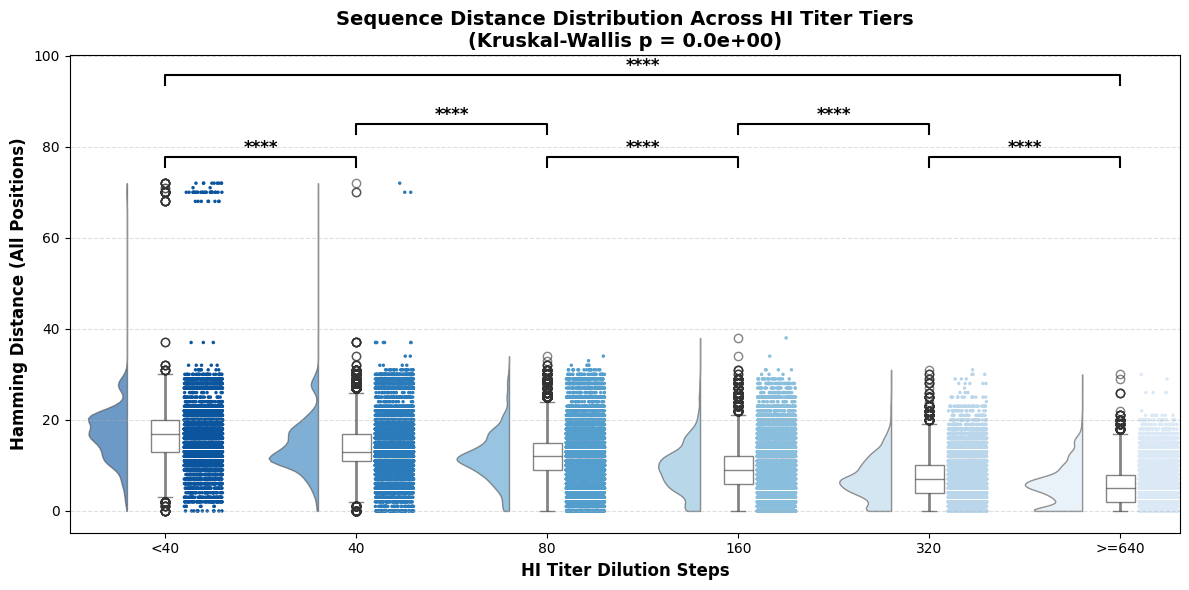

In [123]:
from scipy.stats import kruskal
import matplotlib.pyplot as plt
import seaborn as sns
import scikit_posthocs as sp
import ptitprince as pt

# Filter out Invalid, Missing, and sparse entries
df_grouped = df_plot[df_plot['Titre_Group'].isin(valid_groups)].copy()

# --- 2. STATISTICAL TEST ---
groups_for_test = [group['Distance_All'].values for name, group in df_grouped.groupby('Titre_Group')]
stat, p_value = kruskal(*groups_for_test)
print(f"Kruskal-Wallis Test across Titer Groups -> Stat: {stat:.2f}, p-value: {p_value:.2e}")

# Run Dunn's test for pairwise p-values
dunn_results2 = sp.posthoc_dunn(
    df_grouped,
    val_col='Distance_All',
    group_col='Titre_Group',
    p_adjust='bonferroni'
)

# --- 3. TRUE RAINCLOUD PLOT SETUP ---
plt.figure(figsize=(12, 6))
ax = plt.gca()

# NOTE: ptitprince relies on an older seaborn violinplot/stripplot API.
# If you're on seaborn>=0.13 and this call errors on `bw`/`scale`,
# either pin `seaborn<0.12` or patch ptitprince.
pt.RainCloud(
    data=df_grouped,
    x='Titre_Group',
    y='Distance_All',
    order=valid_groups,
    palette='Blues_r',
    bw=0.2,
    width_viol=0.6,
    ax=ax,
    orient='v',
    move=0.2,
    alpha=0.6,
    cut=0,              # keep the KDE cloud within the actual data range
    point_size=2.5       # correct kwarg name (was 'size')
)
# Don't reassign ax = pt.RainCloud(...) — return type isn't consistent
# across ptitprince versions, and ax is already the target Axes.

# --- 4. ADD STATISTICAL BRACKETS ---
def get_asterisks(p):
    if p <= 0.0001: return '****'
    elif p <= 0.001: return '***'
    elif p <= 0.01: return '**'
    elif p <= 0.05: return '*'
    return 'ns'

def add_bracket(ax, x1, x2, y, h, p_val):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, color='black')
    ax.text((x1 + x2) / 2, y + h, get_asterisks(p_val), ha='center', va='bottom',
             color='black', fontsize=12, weight='bold')

y_min = df_grouped['Distance_All'].min()
y_max = df_grouped['Distance_All'].max()
y_range = y_max - y_min
h = max(y_range * 0.03, 0.5)   # scale bracket height to the data, not a fixed constant

# Loop through all consecutive groups for stepwise significance brackets
for i in range(len(valid_groups) - 1):
    p_val = dunn_results2.loc[valid_groups[i], valid_groups[i + 1]]
    y_pos = y_max + y_range * 0.05 + (i % 2) * y_range * 0.10
    add_bracket(ax, i, i + 1, y_pos, h, p_val)

# Add the extreme comparison (first vs last group) at the very top
p_extreme = dunn_results2.loc[valid_groups[0], valid_groups[-1]]
top_y = y_max + y_range * 0.30
add_bracket(ax, 0, len(valid_groups) - 1, top_y, h, p_extreme)

# --- 5. FINAL FORMATTING ---
plt.title(f'Sequence Distance Distribution Across HI Titer Tiers\n(Kruskal-Wallis p = {p_value:.1e})',
          fontsize=14, weight='bold')
plt.xlabel('HI Titer Dilution Steps', fontsize=12, weight='bold')
plt.ylabel('Hamming Distance (All Positions)', fontsize=12, weight='bold')
plt.xticks(rotation=0, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4, axis='y')

# Expand y-axis so top brackets fit comfortably
plt.ylim(top=top_y + h * 3)

plt.tight_layout()
plt.savefig("HI_vs_All_raincloud.png", dpi=300)
plt.show()

/tmp/ipykernel_2656383/1585787085.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups_for_test = [group['Distance_Epitope'].values for name, group in df_grouped.groupby('Titre_Group')]
/home/apone/fluml_gpu/lib64/python3.9/site-packages/ptitprince/PtitPrince.py:154: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_name, group_df in self.plot_data.groupby(grouping_vars):


Kruskal-Wallis Test across Titer Groups -> Stat: 39600.52, p-value: 0.00e+00


/home/apone/fluml_gpu/lib64/python3.9/site-packages/ptitprince/PtitPrince.py:1070: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


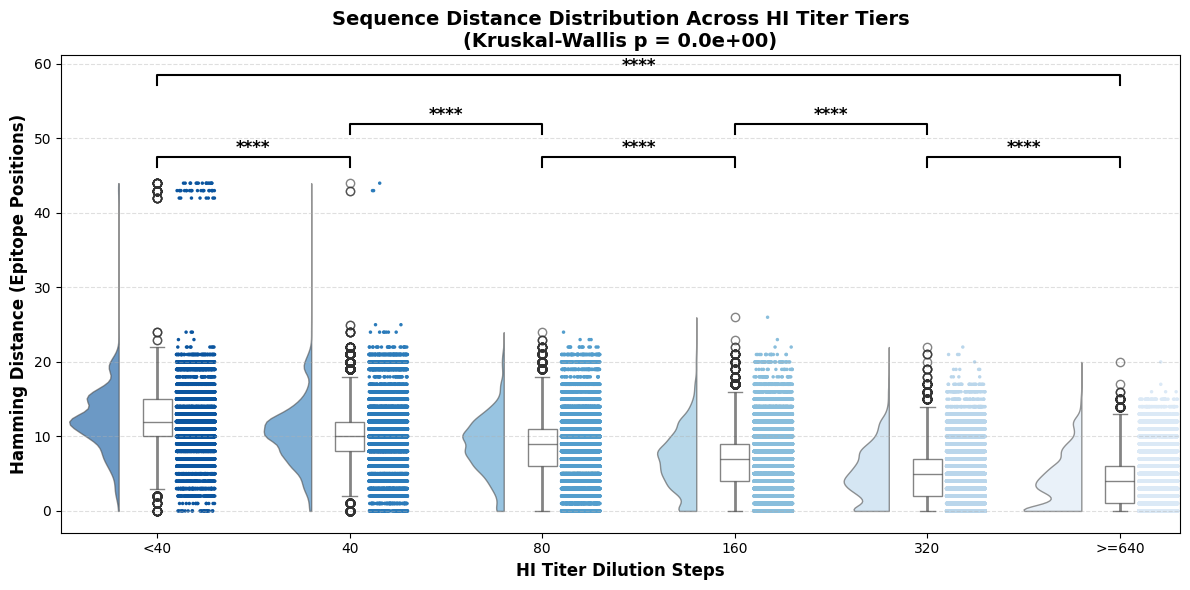

In [124]:
from scipy.stats import kruskal
import matplotlib.pyplot as plt
import seaborn as sns
import scikit_posthocs as sp
import ptitprince as pt

# Filter out Invalid, Missing, and sparse entries
df_grouped = df_plot[df_plot['Titre_Group'].isin(valid_groups)].copy()

# --- 2. STATISTICAL TEST ---
groups_for_test = [group['Distance_Epitope'].values for name, group in df_grouped.groupby('Titre_Group')]
stat, p_value = kruskal(*groups_for_test)
print(f"Kruskal-Wallis Test across Titer Groups -> Stat: {stat:.2f}, p-value: {p_value:.2e}")

# Run Dunn's test for pairwise p-values
dunn_results = sp.posthoc_dunn(
    df_grouped,
    val_col='Distance_Epitope',
    group_col='Titre_Group',
    p_adjust='bonferroni'
)

# --- 3. TRUE RAINCLOUD PLOT SETUP ---
plt.figure(figsize=(12, 6))
ax = plt.gca()

# NOTE: ptitprince relies on an older seaborn violinplot/stripplot API.
# If you're on seaborn>=0.13 and this call errors on `bw`/`scale`,
# either pin `seaborn<0.12` or patch ptitprince.
pt.RainCloud(
    data=df_grouped,
    x='Titre_Group',
    y='Distance_Epitope',
    order=valid_groups,
    palette='Blues_r',
    bw=0.2,
    width_viol=0.6,
    ax=ax,
    orient='v',
    move=0.2,
    alpha=0.6,
    cut=0,              # keep the KDE cloud within the actual data range
    point_size=2.5       # correct kwarg name (was 'size')
)
# Don't reassign ax = pt.RainCloud(...) — return type isn't consistent
# across ptitprince versions, and ax is already the target Axes.

# --- 4. ADD STATISTICAL BRACKETS ---
def get_asterisks(p):
    if p <= 0.0001: return '****'
    elif p <= 0.001: return '***'
    elif p <= 0.01: return '**'
    elif p <= 0.05: return '*'
    return 'ns'

def add_bracket(ax, x1, x2, y, h, p_val):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, color='black')
    ax.text((x1 + x2) / 2, y + h, get_asterisks(p_val), ha='center', va='bottom',
             color='black', fontsize=12, weight='bold')

y_min = df_grouped['Distance_Epitope'].min()
y_max = df_grouped['Distance_Epitope'].max()
y_range = y_max - y_min
h = max(y_range * 0.03, 0.5)   # scale bracket height to the data, not a fixed constant

# Loop through all consecutive groups for stepwise significance brackets
for i in range(len(valid_groups) - 1):
    p_val = dunn_results.loc[valid_groups[i], valid_groups[i + 1]]
    y_pos = y_max + y_range * 0.05 + (i % 2) * y_range * 0.10
    add_bracket(ax, i, i + 1, y_pos, h, p_val)

# Add the extreme comparison (first vs last group) at the very top
p_extreme = dunn_results.loc[valid_groups[0], valid_groups[-1]]
top_y = y_max + y_range * 0.30
add_bracket(ax, 0, len(valid_groups) - 1, top_y, h, p_extreme)

# --- 5. FINAL FORMATTING ---
plt.title(f'Sequence Distance Distribution Across HI Titer Tiers\n(Kruskal-Wallis p = {p_value:.1e})',
          fontsize=14, weight='bold')
plt.xlabel('HI Titer Dilution Steps', fontsize=12, weight='bold')
plt.ylabel('Hamming Distance (Epitope Positions)', fontsize=12, weight='bold')
plt.xticks(rotation=0, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4, axis='y')

# Expand y-axis so top brackets fit comfortably
plt.ylim(top=top_y + h * 3)

plt.tight_layout()
plt.savefig("HI_vs_EPI_raincloud.png", dpi=300)
plt.show()

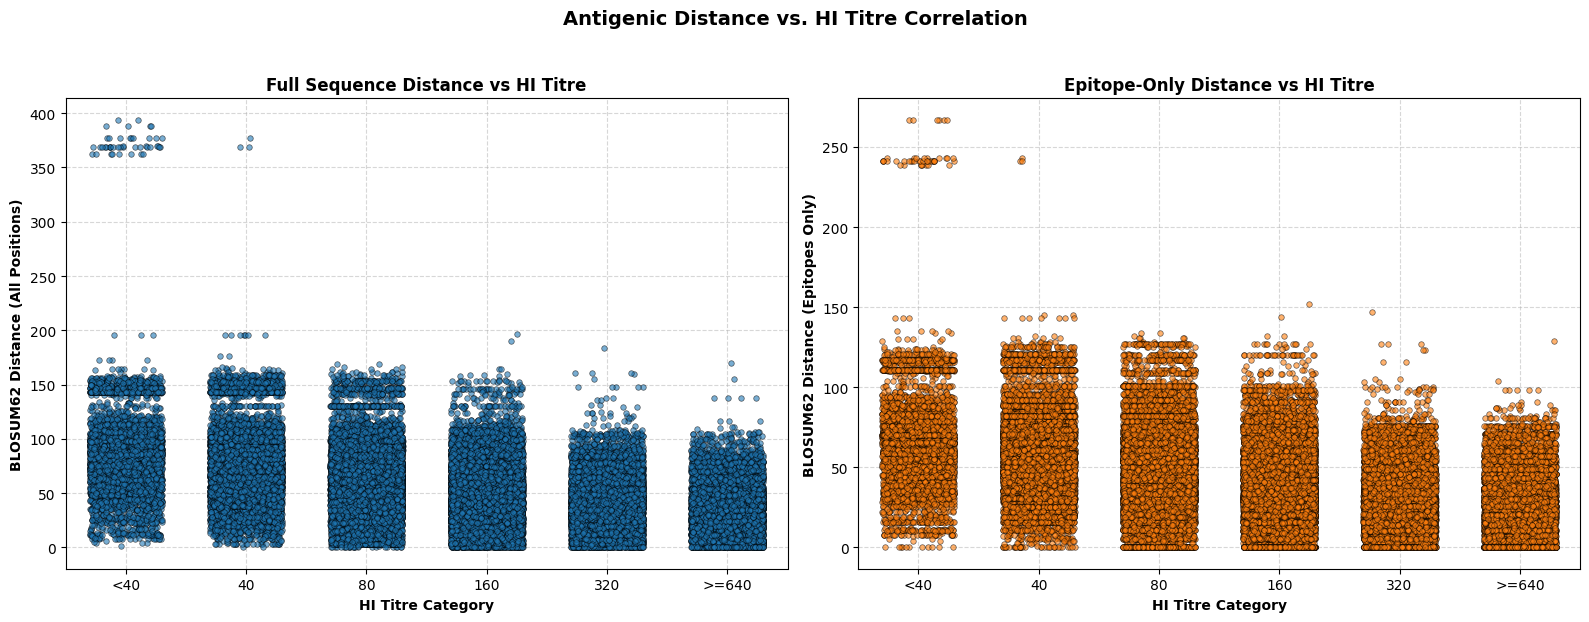

In [91]:
import seaborn as sns
import matplotlib.pyplot as plt

if not df_plot.empty:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Define the order so the text strings plot correctly left-to-right
    titer_order = ["<40", "40", "80", "160", "320", ">=640"]
    
    # Plot 1: All Positions (Using stripplot)
    sns.stripplot(
        data=df_plot, x='Titre_Group', y='Distance_All', order=titer_order,
        color='tab:blue', alpha=0.6, edgecolor='k', linewidth=0.5, size=4, ax=axes[0], jitter=0.3
    )
    axes[0].set_title('Full Sequence Distance vs HI Titre', fontsize=12, weight='bold')
    axes[0].set_xlabel('HI Titre Category', fontsize=10, weight='bold')
    axes[0].set_ylabel('BLOSUM62 Distance (All Positions)', fontsize=10, weight='bold')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    # Plot 2: Epitope Positions Only
    sns.stripplot(
        data=df_plot, x='Titre_Group', y='Distance_Epitope', order=titer_order,
        color='tab:orange', alpha=0.6, edgecolor='k', linewidth=0.5, size=4, ax=axes[1], jitter=0.3
    )
    axes[1].set_title('Epitope-Only Distance vs HI Titre', fontsize=12, weight='bold')
    axes[1].set_xlabel('HI Titre Category', fontsize=10, weight='bold')
    axes[1].set_ylabel('BLOSUM62 Distance (Epitopes Only)', fontsize=10, weight='bold')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.suptitle('Antigenic Distance vs. HI Titre Correlation', fontsize=14, weight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
else:
    print("No valid pairs found to plot.")

In [94]:
df_plot.head()

,Virus_Name,Serum_Name,Distance_All,Distance_Epitope,Titre_Group,HI_Titre_Raw
1,A/Alabama/05/2010,A/Rhode Island/01/2010,60.0,44.0,320,320
3,A/Taiwan/851/2010,A/Perth/10/2010,88.0,57.0,>=640,640
4,A/England/270/2010,A/Perth/10/2010,37.0,26.0,>=640,640
5,A/Netherlands/34/2010,A/Perth/10/2010,42.0,32.0,320,320
6,A/Galati/47519/2011,A/Perth/10/2010,22.0,13.0,>=640,5120


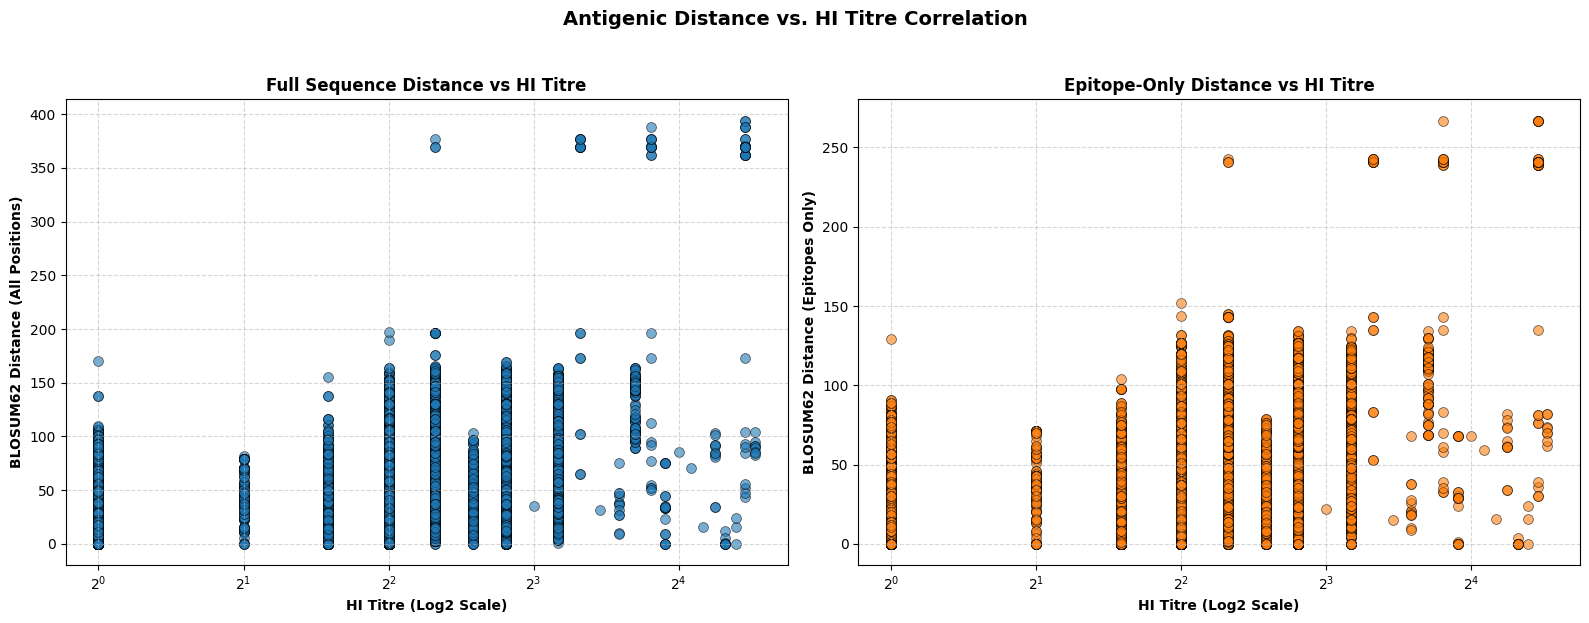

In [95]:
# --- 5. DUAL SCATTER PLOTS (ALL vs EPITOPE) ---
if not df_plot.empty:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Plot 1: All Positions
    sns.scatterplot(
        data=df_plot, x='HI_Titre_Raw', y='Distance_All', 
        color='tab:blue', alpha=0.6, edgecolor='k', s=50, ax=axes[0]
    )
    axes[0].set_xscale('log', base=2)
    axes[0].set_title('Full Sequence Distance vs HI Titre', fontsize=12, weight='bold')
    axes[0].set_xlabel('HI Titre (Log2 Scale)', fontsize=10, weight='bold')
    axes[0].set_ylabel('BLOSUM62 Distance (All Positions)', fontsize=10, weight='bold')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    # Plot 2: Epitope Positions Only
    sns.scatterplot(
        data=df_plot, x='HI_Titre_Raw', y='Distance_Epitope', 
        color='tab:orange', alpha=0.6, edgecolor='k', s=50, ax=axes[1]
    )
    axes[1].set_xscale('log', base=2)
    axes[1].set_title('Epitope-Only Distance vs HI Titre', fontsize=12, weight='bold')
    axes[1].set_xlabel('HI Titre (Log2 Scale)', fontsize=10, weight='bold')
    axes[1].set_ylabel('BLOSUM62 Distance (Epitopes Only)', fontsize=10, weight='bold')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.suptitle('Antigenic Distance vs. HI Titre Correlation', fontsize=14, weight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
else:
    print("No valid pairs found to plot.")